# EUMETSAT Data Tailor: one-scan diagnostic

This notebook creates a small, reproducible support case for the spatial mismatch we saw with Data Tailor Web Service (DTWS). It uses **one** SEVIRI RSS scan: 19 January 2024, nominal 12:00 UTC.

It will (1) search for that scan, (2) download its original native product, (3) submit one Data Tailor job for the GB-area crop, and (4) compare scientific natural-colour RGB composites from the source and tailored data with EUMETSAT’s same-time enhanced RGB preview, first over GB and then over the full geographic extent of the RSS scan. This is a targeted experiment, not the week-long PVNet pipeline.

All files for this diagnostic are kept under `Luke/data/to_gitignore/data_tailor_diagnostics/jan19_2024/`, separate from the PVNet testing datasets. `FRESH_SOURCE_DOWNLOAD=True` creates a new timestamped source archive and measures its transfer time; set it to `False` to reuse the latest source in this diagnostic folder. Tailored outputs are reused unless the relevant `FORCE_*` switch is enabled. EUMDAC credentials are requested securely when needed; do not paste them into notebook cells or chat.

The client/API runs on your Mac, but DTWS does the actual tailoring remotely. The figures use standard SEVIRI natural-colour channel assignments and are designed to show spatial coverage and scene structure; the EUMETSAT preview is an enhanced rendered image, so its colours and contrast need not match the data-derived composites.


## 1. Configure the single-scan case

In [22]:
from pathlib import Path
import datetime as dt
import getpass
import os

# Support running this notebook with the current directory at PVNet/ or PVNet/Luke/.
if not (Path.cwd() / "data").is_dir() and (Path.cwd() / "Luke" / "data").is_dir():
    os.chdir(Path.cwd() / "Luke")

CASE_START_UTC = dt.datetime(2024, 1, 19, 12, 0, 0)
CASE_END_UTC = dt.datetime(2024, 1, 19, 12, 6, 0)
COLLECTION_ID = "EO:EUM:DAT:MSG:MSG15-RSS"
EXPECTED_PRODUCT_TIME = "20240119120416"  # scan ending at about 12:04:16 UTC
ROI_NSWE = {"NSWE": [61.2, 49.7, -8.8, 2.0]}  # north, south, west, east
# Keep all inputs and outputs for this diagnostic separate from other notebook data.
OUTPUT_DIR = Path("data/to_gitignore/data_tailor_diagnostics/jan19_2024")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_DIR = OUTPUT_DIR / "source_downloads"
TAILORED_DIR = OUTPUT_DIR / "tailored_outputs"
SOURCE_DIR.mkdir(exist_ok=True)
TAILORED_DIR.mkdir(exist_ok=True)

# True downloads a fresh original source product and stamps the archive filename.
# False reuses the most recently downloaded source in this diagnostic folder.
FRESH_SOURCE_DOWNLOAD = True
FORCE_TAILOR_JOB = False

consumer_key = os.getenv("EUMETSAT_CONSUMER_KEY") or getpass.getpass("EUMETSAT Consumer Key: ")
consumer_secret = os.getenv("EUMETSAT_CONSUMER_SECRET") or getpass.getpass("EUMETSAT Consumer Secret: ")
if not consumer_key or not consumer_secret:
    raise ValueError("Both EUMETSAT credentials are required.")

print("Case: 2024-01-19 12:00 UTC, one RSS scan")
print("ROI (N, S, W, E):", ROI_NSWE["NSWE"])
print("Diagnostics-only output directory:", OUTPUT_DIR.resolve())
print("Fresh source download:", FRESH_SOURCE_DOWNLOAD)
print("No request has been submitted yet.")


Case: 2024-01-19 12:00 UTC, one RSS scan
ROI (N, S, W, E): [61.2, 49.7, -8.8, 2.0]
Diagnostics-only output directory: /Users/mans5211/GitHub-repos/PVNet/Luke/data/to_gitignore/data_tailor_diagnostics/jan19_2024
Fresh source download: True
No request has been submitted yet.


## 2. Find the exact RSS product

In [23]:
import eumdac

token = eumdac.AccessToken((consumer_key, consumer_secret), validity=3600, cache=False)
datastore = eumdac.DataStore(token)
collection = datastore.get_collection(COLLECTION_ID)
products = list(collection.search(
    dtstart=CASE_START_UTC,
    dtend=CASE_END_UTC,
    bbox="-8.8, 49.7, 2.0, 61.2",  # west, south, east, north
    set="brief",
))

matching = [p for p in products if EXPECTED_PRODUCT_TIME in "".join(ch for ch in str(p) if ch.isdigit())]
if len(matching) != 1:
    raise LookupError(
        f"Expected exactly one product containing {EXPECTED_PRODUCT_TIME}; "
        f"found {len(matching)}. Products returned: {[str(p) for p in products]}"
    )
product = matching[0]
print("Selected source product:", product)
print("Search returned", len(products), "products; only the matching noon scan will be downloaded and tailored.")


Selected source product: MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA
Search returned 2 products; only the matching noon scan will be downloaded and tailored.


## 3. Download the original source scan

This cell either downloads one fresh original RSS product or reuses the latest source archive in the diagnostics-only folder. A fresh download receives a UTC timestamp in its filename, and the cell reports the transfer duration and rate. It then extracts the native `.nat` file into a matching run-specific subfolder. This source is used by the local Satpy figures and provides the input product for the Data Tailor request.


In [24]:
import shutil
import time
import zipfile

if FRESH_SOURCE_DOWNLOAD:
    download_id = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    source_zip = SOURCE_DIR / f"{product}_download_{download_id}.zip"
else:
    cached_archives = sorted(SOURCE_DIR.glob(f"{product}_download_*.zip"))
    if not cached_archives:
        raise FileNotFoundError(
            f"No previous source archive found in {SOURCE_DIR}. Set FRESH_SOURCE_DOWNLOAD=True first."
        )
    source_zip = cached_archives[-1]
    download_id = source_zip.stem.rsplit("_download_", 1)[-1]

native_run_dir = SOURCE_DIR / f"native_{download_id}"
native_run_dir.mkdir(parents=True, exist_ok=True)

download_seconds = 0.0
if FRESH_SOURCE_DOWNLOAD:
    partial = source_zip.with_suffix(".zip.part")
    print(f"Downloading a fresh source product to {source_zip.name} ...")
    download_started = time.perf_counter()
    try:
        with product.open() as source, partial.open("wb") as target:
            shutil.copyfileobj(source, target)
        with zipfile.ZipFile(partial) as archive:
            bad_member = archive.testzip()
            if bad_member is not None:
                raise RuntimeError(f"Corrupt ZIP member: {bad_member}")
        partial.replace(source_zip)
    except Exception:
        partial.unlink(missing_ok=True)
        raise
    download_seconds = time.perf_counter() - download_started
    downloaded_mb = source_zip.stat().st_size / 1e6
    print(f"Downloaded {downloaded_mb:.1f} MB in {download_seconds:.1f} s")
    print(f"Average transfer rate: {downloaded_mb / max(download_seconds, 1e-9):.2f} MB/s")
else:
    print(f"Reusing source archive: {source_zip} ({source_zip.stat().st_size / 1e6:.1f} MB)")

with zipfile.ZipFile(source_zip) as archive:
    nat_members = [name for name in archive.namelist() if name.lower().endswith(".nat")]
    if len(nat_members) != 1:
        raise ValueError(f"Expected one .nat member in {source_zip.name}; found {nat_members}")
    native_path = native_run_dir / Path(nat_members[0]).name
    if not native_path.exists():
        extract_started = time.perf_counter()
        with archive.open(nat_members[0]) as src, native_path.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        print(f"Extracted native scan in {time.perf_counter() - extract_started:.1f} s")
print(f"Native scan for run {download_id}: {native_path.name} ({native_path.stat().st_size / 1e6:.1f} MB)")


Downloaded 60.4 MB in 4.5 s
Average transfer rate: 13.29 MB/s
Extracted native scan in 0.2 s
Native scan for run 20261117T180718Z: MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA.nat (102.2 MB)


## 4. Submit one Data Tailor Web Service job

This intentionally reproduces the earlier GB crop configuration: all 11 non-HRV channels, geographic output, bilinear resampling, 0.05° longitude × 0.03° latitude grid, and the ROI above. It saves the returned archive locally and reuses it on reruns. A fresh tailoring request is made only if no output exists or `FORCE_TAILOR_JOB=True`.

In [25]:
import fnmatch
import time
from eumdac import tailor_models

tailored_archives = sorted(TAILORED_DIR.glob("*.zip"))
# Keep reusing the earlier diagnostic's completed GB-tailored output if present;
# copy it into the new diagnostics-only folder rather than reprocessing it.
legacy_gb_dir = Path("data/to_gitignore/data_tailor_case_jan19/tailored")
if not tailored_archives and not FORCE_TAILOR_JOB:
    legacy_gb_archives = sorted(legacy_gb_dir.glob("HRSEVIRI_*.zip"), key=lambda p: p.stat().st_mtime)
    if legacy_gb_archives:
        legacy_gb = legacy_gb_archives[-1]
        copied_gb = TAILORED_DIR / legacy_gb.name
        shutil.copy2(legacy_gb, copied_gb)
        tailored_archives = [copied_gb]
        print(f"Copied completed earlier diagnostic output into this diagnostics folder: {copied_gb.name}")
if FORCE_TAILOR_JOB:
    for old_file in tailored_archives:
        old_file.unlink()
    tailored_archives = []

if tailored_archives:
    print("Reusing existing tailored archive:")
    for path in tailored_archives:
        print(f"- {path.name} ({path.stat().st_size / 1e6:.2f} MB)")
else:
    tailoring = eumdac.DataTailor(token)
    chain = tailor_models.Chain(
        product="HRSEVIRI",
        format="netcdf4",
        filter={"bands": [f"channel_{i}" for i in range(1, 12)]},
        projection="geographic",
        resample_method="bilinear",
        resample_resolution=[0.05, 0.03],  # longitude, latitude in degrees
        roi=ROI_NSWE,
        compression={"format": "zip"},
    )
    print("Submitting one Data Tailor job for:", product)
    print("Settings: NetCDF4; channels 1–11; geographic; bilinear; 0.05° × 0.03°; ROI N/S/W/E =", ROI_NSWE["NSWE"])
    job = tailoring.new_customisation(product, chain=chain)
    while True:
        status = job.status
        print("  status:", status)
        if status == "DONE":
            break
        if status in {"ERROR", "FAILED", "KILLED", "DELETED", "INACTIVE"}:
            raise RuntimeError(
                f"Data Tailor job ended with status {status}. Open this job in the EUMETSAT portal and save its job ID/log for support."
            )
        time.sleep(10)

    output_names = fnmatch.filter(job.outputs, "*")
    if not output_names:
        raise RuntimeError("Data Tailor reported DONE but returned no output files.")
    for output_name in output_names:
        destination = TAILORED_DIR / Path(output_name).name
        partial = destination.with_suffix(destination.suffix + ".part")
        with job.stream_output(output_name) as src, partial.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        partial.replace(destination)
        print(f"Saved {destination.name} ({destination.stat().st_size / 1e6:.2f} MB)")
    job.delete()
    tailored_archives = sorted(TAILORED_DIR.glob("*.zip"))


Copied completed earlier diagnostic output into this diagnostics folder: HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_792a21f2_FPRC.zip
Reusing existing tailored archive:
- HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_792a21f2_FPRC.zip (3.46 MB)


## 5. Compare natural-colour RGB over Great Britain

This figure shows three views of the same 12:00 UTC scene: the original native scan locally calibrated and resampled to the tailored grid, the tailored channel values rendered as a natural-colour-style RGB, and EUMETSAT’s `rgb_naturalenhncd_nrt` preview requested for the same time and area.

The channel assignment is the standard SEVIRI natural-colour combination: **red = 1.6 μm (IR_016), green = 0.8 μm (VIS008), blue = 0.6 μm (VIS006)**. Satpy creates the source composite with its natural-colour enhancement; the tailored values receive a display-only contrast stretch. The EUMETSAT preview is itself enhanced, so compare coastlines, cloud patterns and coverage rather than exact pixel colours or brightness.


Tailored archive: HRSEVIRI_20240119T120008Z_20240119T120416Z_epct_792a21f2_FPRC.zip
Archive size: 3.46 MB
NetCDF dimensions: {'lat': 288, 'lon': 270}
Variables: ['crs', 'channel_1', 'channel_2', 'channel_3', 'channel_4', 'channel_5', 'channel_6', 'channel_7', 'channel_8', 'channel_9', 'channel_10', 'channel_11']
Processing metadata: {'EPCT_projection': 'geographic', 'EPCT_roi': 'custom', 'EPCT_geospatial_lat_min': '-70.7011306', 'EPCT_geospatial_lat_max': '70.7054108'}


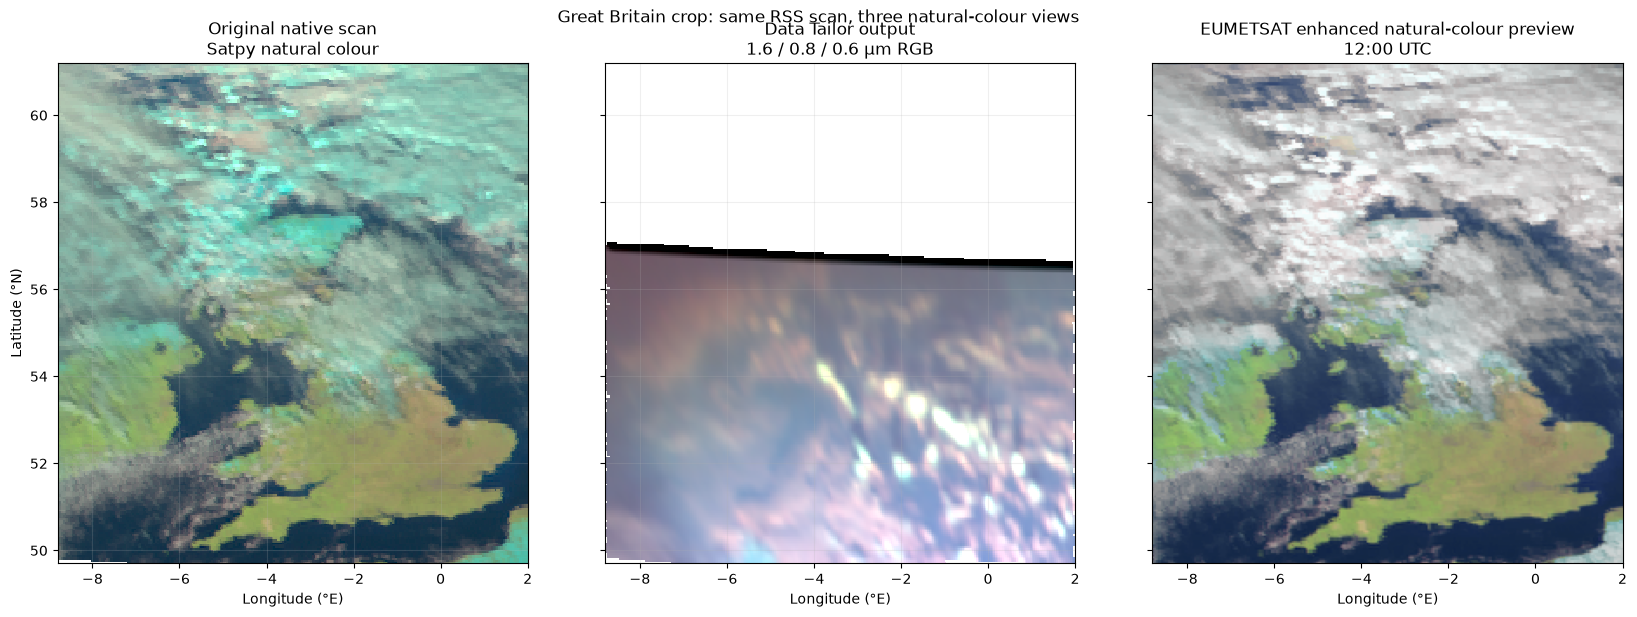

In [26]:
import io
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import requests
from PIL import Image as PILImage
from satpy import Scene
from satpy.enhancements.enhancer import get_enhanced_image
from pyresample.geometry import AreaDefinition
from pyproj import Transformer

if len(tailored_archives) != 1:
    raise ValueError(f"Expected one tailored ZIP, found {tailored_archives}")
with zipfile.ZipFile(tailored_archives[0]) as archive:
    nc_members = [name for name in archive.namelist() if name.lower().endswith((".nc", ".nc4"))]
    if len(nc_members) != 1:
        raise ValueError(f"Expected one NetCDF member, found {nc_members}")
    with xr.open_dataset(io.BytesIO(archive.read(nc_members[0])), engine="h5netcdf") as ds:
        print("Tailored archive:", tailored_archives[0].name)
        print("Archive size:", f"{tailored_archives[0].stat().st_size / 1e6:.2f} MB")
        print("NetCDF dimensions:", dict(ds.sizes))
        print("Variables:", list(ds.data_vars))
        print("Processing metadata:", {
            k: ds.attrs.get(k) for k in
            ("EPCT_projection", "EPCT_roi", "EPCT_geospatial_lat_min", "EPCT_geospatial_lat_max")
        })
        required = ["channel_1", "channel_2", "channel_3", "lat", "lon"]
        missing = [name for name in required if name not in ds]
        if missing:
            raise KeyError(f"Missing expected tailored variables: {missing}")
        # EUMETSAT's NetCDF channel numbering: 1=VIS006, 2=VIS008, 3=IR_016.
        tail_blue = ds["channel_1"].values.astype(np.float32)
        tail_green = ds["channel_2"].values.astype(np.float32)
        tail_red = ds["channel_3"].values.astype(np.float32)
        tail_lats = ds["lat"].values.astype(float)
        tail_lons = ds["lon"].values.astype(float)
        fill_values = [
            float(ds.attrs[f"ch{i:02d}_cal"].split()[0])
            for i in (1, 2, 3)
        ]
        tail_valid = np.isfinite(tail_red) & np.isfinite(tail_green) & np.isfinite(tail_blue)
        for band, fill in zip((tail_blue, tail_green, tail_red), fill_values):
            if np.isfinite(fill):
                tail_valid &= ~np.isclose(band, fill, atol=1e-6)
        tail_raw_rgb = np.stack([tail_red, tail_green, tail_blue], axis=-1)

# Stretch each display channel independently over valid GB pixels. This is only
# for visualization; it does not alter the saved scientific NetCDF values.
def contrast_stretch_rgb(rgb, valid, low_percentile=2, high_percentile=98):
    output = np.zeros_like(rgb, dtype=np.float32)
    for index in range(3):
        values = rgb[..., index][valid]
        low, high = np.nanpercentile(values, [low_percentile, high_percentile])
        if not np.isfinite(high - low) or high <= low:
            raise ValueError(f"Cannot stretch RGB channel {index}: limits {low}, {high}")
        output[..., index] = np.clip((rgb[..., index] - low) / (high - low), 0, 1)
    # A mild display gamma keeps dark land/cloud detail visible.
    return np.power(output, 0.8)

def rgb_rgba(rgb, valid):
    rgba = np.zeros((*valid.shape, 4), dtype=np.float32)
    rgba[..., :3] = np.nan_to_num(rgb, nan=0.0)
    rgba[..., 3] = valid.astype(np.float32)
    return rgba

def get_natural_colour_preview(west, south, east, north, width, height, crs="EPSG:4326"):
    # WMS 1.3.0 EPSG:4326 uses latitude,longitude order; projected CRSs use x,y.
    if crs.upper() == "EPSG:4326":
        bbox = f"{south},{west},{north},{east}"
    else:
        transformer = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
        corner_x, corner_y = transformer.transform(
            [west, west, east, east], [south, north, south, north]
        )
        bbox = f"{min(corner_x)},{min(corner_y)},{max(corner_x)},{max(corner_y)}"
    response = requests.get(
        "https://view.eumetsat.int/geoserver/ows",
        params={
            "service": "WMS", "request": "GetMap", "version": "1.3.0",
            "layers": "msg_rss:rgb_naturalenhncd_nrt", "styles": "",
            "format": "image/png", "crs": crs,
            "bbox": bbox,
            "width": int(width), "height": int(height),
            "time": "2024-01-19T12:00:00.000Z",
        },
        timeout=90,
    )
    response.raise_for_status()
    if not response.headers.get("Content-Type", "").startswith("image/"):
        raise RuntimeError(f"WMS did not return an image: {response.text[:350]}")
    return np.asarray(PILImage.open(io.BytesIO(response.content)).convert("RGB"))

if tail_lats.ndim != 1 or tail_lons.ndim != 1:
    raise ValueError(f"Expected one-dimensional latitude/longitude axes; got {tail_lats.shape}, {tail_lons.shape}")
lat_step = float(np.median(np.abs(np.diff(tail_lats))))
lon_step = float(np.median(np.abs(np.diff(tail_lons))))
gb_extent = (
    float(tail_lons.min() - lon_step / 2), float(tail_lats.min() - lat_step / 2),
    float(tail_lons.max() + lon_step / 2), float(tail_lats.max() + lat_step / 2),
)
west, south, east, north = gb_extent

gb_area = AreaDefinition(
    "tailored_gb_grid", "Tailored GB geographic grid", "EPSG:4326", "EPSG:4326",
    len(tail_lons), len(tail_lats), gb_extent,
)
source_scene = Scene(filenames=[str(native_path)], reader="seviri_l1b_native")
source_scene.load(["natural_color"], upper_right_corner="NE")
source_gb_scene = source_scene.resample(gb_area, resampler="nearest")
source_rgb = np.asarray(get_enhanced_image(source_gb_scene["natural_color"]).data)
if source_rgb.ndim != 3:
    raise ValueError(f"Unexpected Satpy natural-colour shape: {source_rgb.shape}")
if source_rgb.shape[0] == 3:
    source_rgb = np.moveaxis(source_rgb, 0, -1)
elif source_rgb.shape[-1] != 3:
    raise ValueError(f"Could not identify RGB axis in Satpy array: {source_rgb.shape}")
source_rgb = np.clip(source_rgb, 0, 1)
source_valid = np.all(np.isfinite(source_rgb), axis=-1)
# Satpy's geographic target rows run north-to-south. Match the NetCDF axis order.
if tail_lats[0] < tail_lats[-1]:
    source_rgb = np.flipud(source_rgb)
    source_valid = np.flipud(source_valid)

tail_rgb = contrast_stretch_rgb(tail_raw_rgb, tail_valid)
preview_gb = get_natural_colour_preview(west, south, east, north, len(tail_lons), len(tail_lats))

fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharex=True, sharey=True)
panes = [
    (rgb_rgba(source_rgb, source_valid), "Original native scan\nSatpy natural colour"),
    (rgb_rgba(tail_rgb, tail_valid), "Data Tailor output\n1.6 / 0.8 / 0.6 μm RGB"),
]
for ax, (image, title) in zip(axes[:2], panes):
    ax.imshow(image, extent=(west, east, south, north), origin="lower", interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    ax.grid(alpha=0.2)
axes[2].imshow(preview_gb, extent=(west, east, south, north), origin="upper")
axes[2].set_title("EUMETSAT enhanced natural-colour preview\n12:00 UTC")
axes[2].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
fig.suptitle("Great Britain crop: same RSS scan, three natural-colour views")
fig.tight_layout()


## 6. Compare the full geographic RSS scan with the preview

This view uses the original source scan, resampled to a Web Mercator map spanning the full Earth-visible RSS footprint. The EUMETSAT enhanced natural-colour preview is requested in the same projection and for the same time. Web Mercator makes the full domain fit a taller map panel, but enlarges high-latitude regions; this is a visual comparison, not an area or distance measurement. Pixels outside the scanned footprint remain transparent in the locally rendered image.


Full RSS geographic bounds (W, S, E, N): (-71.72, 12.28, 90.72, 81.76)
Projected comparison grid: 1200 x 1022


Text(0.5, 0.98, 'Full geographic extent of the 9.5°E Rapid Scan product (EPSG:3857)')

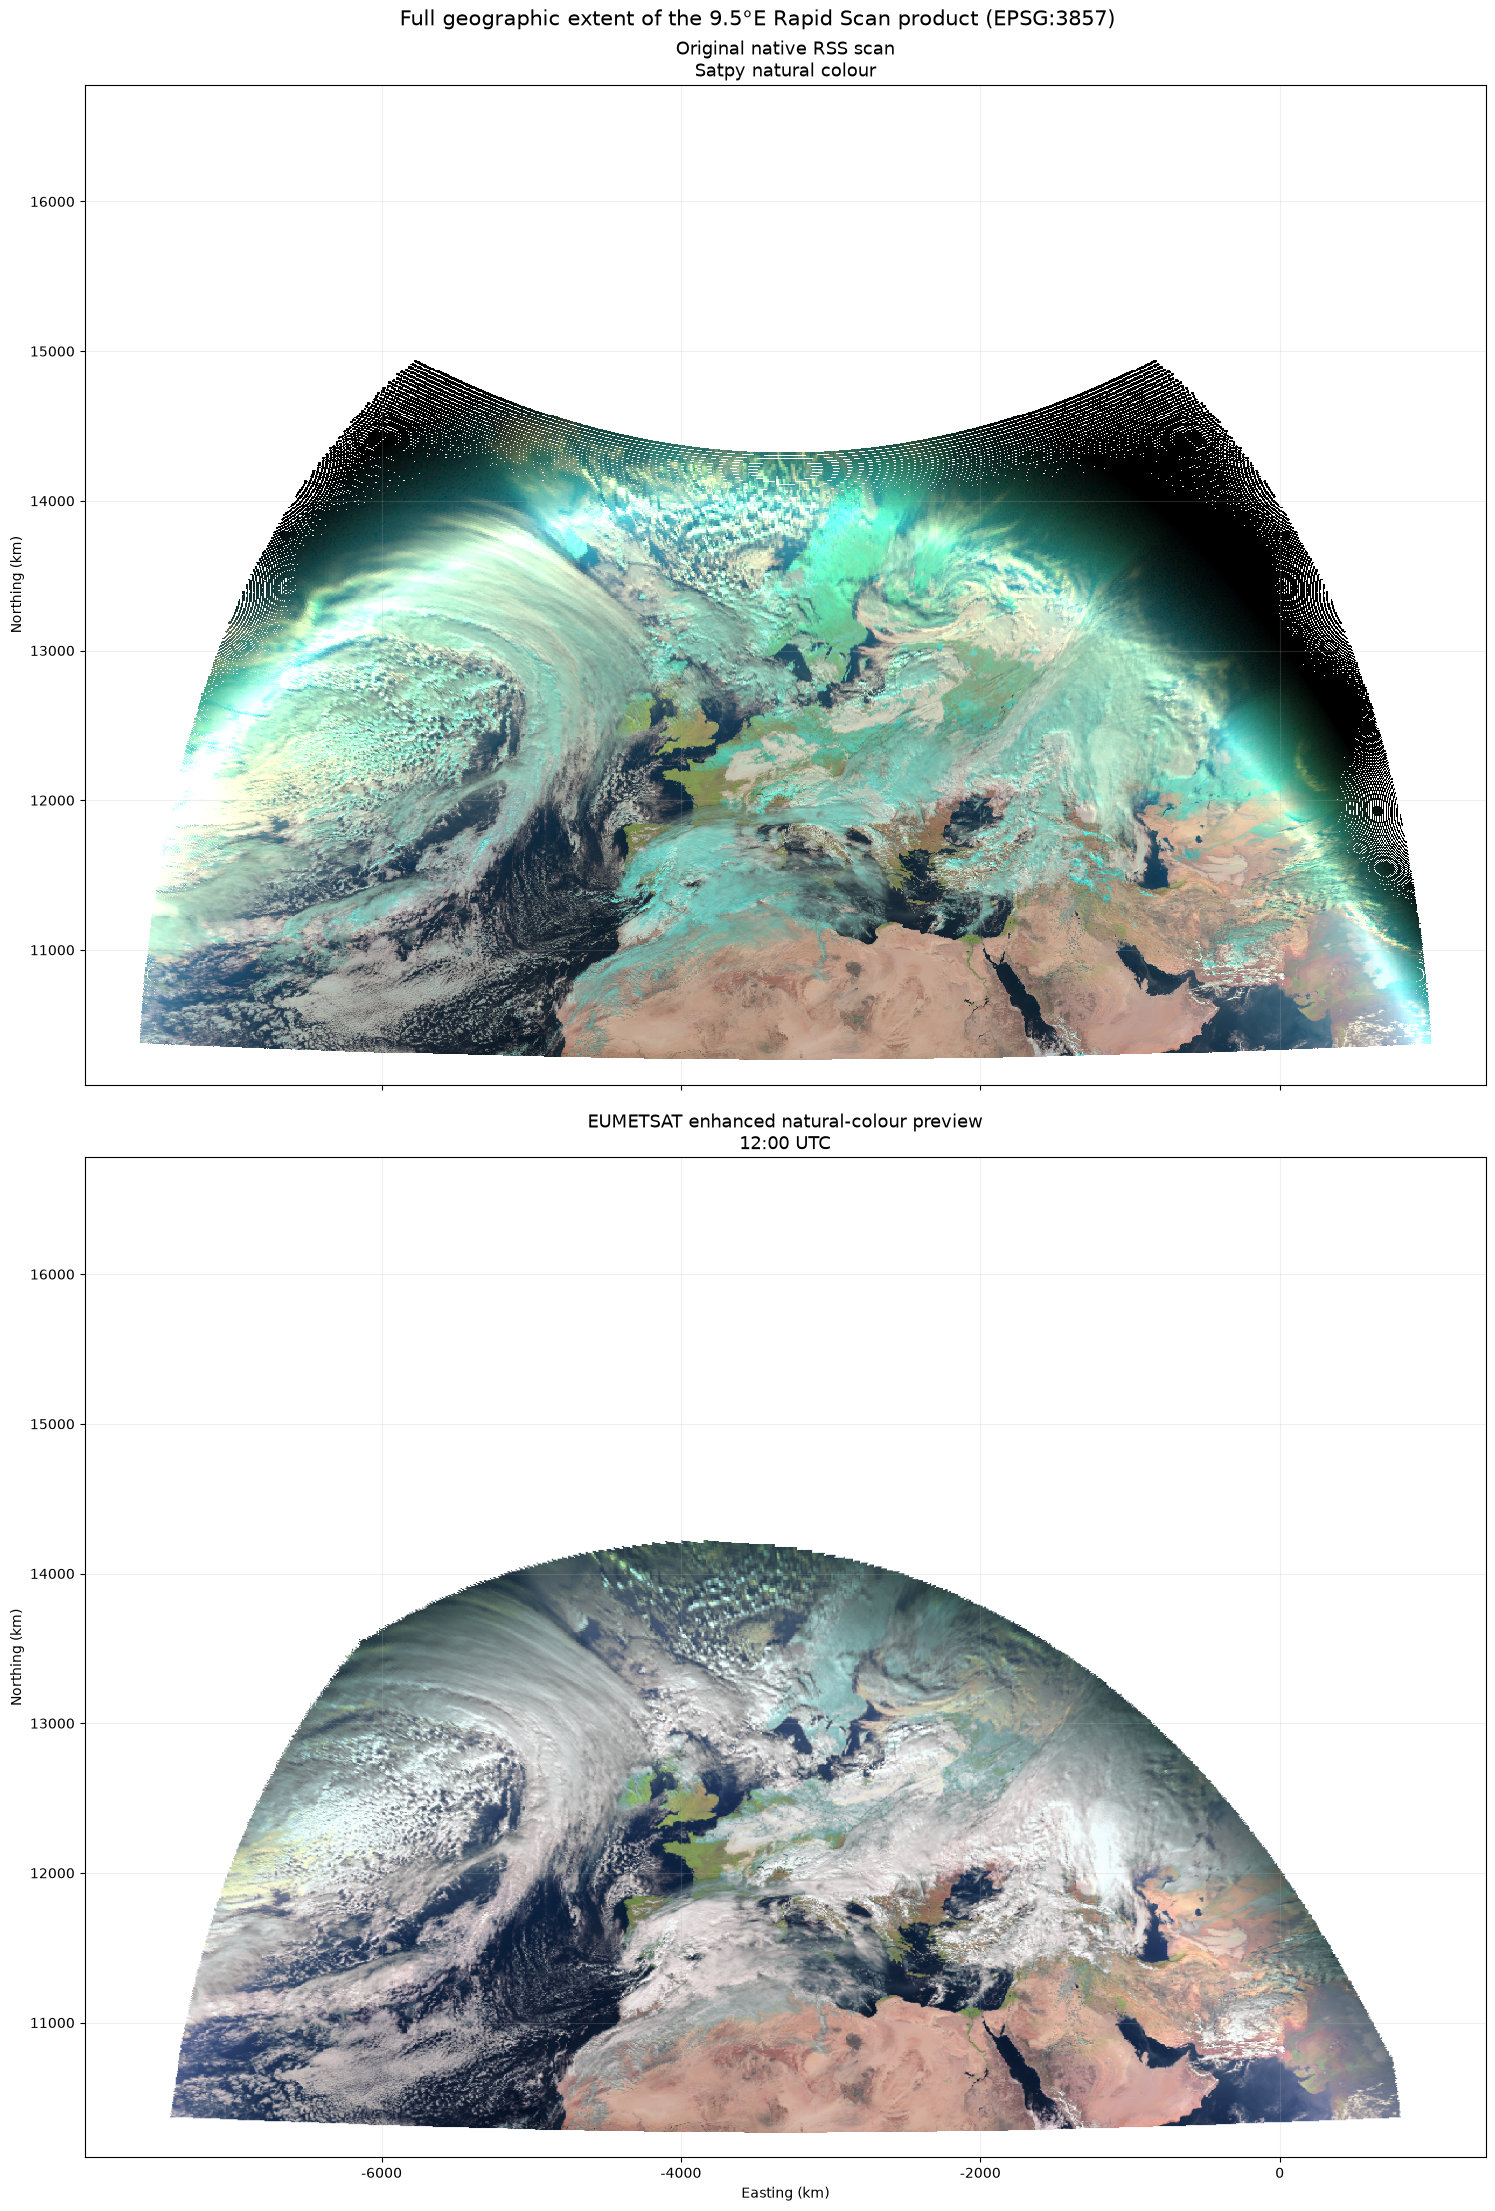

In [27]:
# Derive the full geographic bounds from valid geolocation points in the RSS scan.
native_area = source_scene["natural_color"].attrs.get("area")
if native_area is None:
    raise RuntimeError("Satpy did not provide geostationary area metadata for the source composite.")
native_lons, native_lats = native_area.get_lonlats()
geo_valid = np.isfinite(native_lons) & np.isfinite(native_lats)
if not geo_valid.any():
    raise RuntimeError("Could not derive geographic coordinates for the RSS scan.")
full_west = float(np.nanmin(native_lons[geo_valid]))
full_east = float(np.nanmax(native_lons[geo_valid]))
full_south = float(np.nanmin(native_lats[geo_valid]))
full_north = float(np.nanmax(native_lats[geo_valid]))
# Pad by roughly one degree so the scan's outermost valid pixels are not clipped.
full_west, full_east = max(-180, full_west - 0.5), min(180, full_east + 0.5)
full_south, full_north = max(-89, full_south - 0.5), min(89, full_north + 0.5)

# Project to Web Mercator for a more compact, familiar map shape. The WMS
# preview is requested in the same CRS, so both panels use identical geometry.
# Web Mercator stretches high latitudes; use this view for visual comparison,
# not for measuring areas or distances.
map_crs = "EPSG:3857"
projector = Transformer.from_crs("EPSG:4326", map_crs, always_xy=True)
corner_x, corner_y = projector.transform(
    [full_west, full_west, full_east, full_east],
    [full_south, full_north, full_south, full_north],
)
projected_extent = (
    float(min(corner_x)), float(min(corner_y)),
    float(max(corner_x)), float(max(corner_y)),
)
projected_width = projected_extent[2] - projected_extent[0]
projected_height = projected_extent[3] - projected_extent[1]
full_width = 1200
full_height = max(500, int(round(full_width * projected_height / projected_width)))
full_area = AreaDefinition(
    "rss_full_web_mercator", "Full geographic RSS footprint, Web Mercator",
    map_crs, map_crs, full_width, full_height, projected_extent,
)
full_scene = source_scene.resample(full_area, resampler="nearest")
full_rgb_array = np.asarray(get_enhanced_image(full_scene["natural_color"]).data)
if full_rgb_array.shape[0] == 3:
    full_rgb = np.moveaxis(full_rgb_array, 0, -1)
elif full_rgb_array.shape[-1] == 3:
    full_rgb = full_rgb_array
else:
    raise ValueError(f"Could not identify RGB axis in full Satpy composite: {full_rgb_array.shape}")
full_rgb = np.clip(full_rgb, 0, 1)
full_valid = np.all(np.isfinite(full_rgb), axis=-1)
# AreaDefinition output is north-to-south, suitable for imshow(origin="upper").
full_rgba = rgb_rgba(full_rgb, full_valid)
preview_full = get_natural_colour_preview(
    full_west, full_south, full_east, full_north,
    full_width, full_height, crs=map_crs,
)

print("Full RSS geographic bounds (W, S, E, N):", tuple(round(v, 2) for v in full_extent))
print("Projected comparison grid:", full_width, "x", full_height)
fig, axes = plt.subplots(2, 1, figsize=(15, 22), sharex=True, sharey=True, constrained_layout=True)
axes[0].imshow(full_rgba, extent=projected_extent, origin="upper", interpolation="nearest")
axes[0].set_title("Original native RSS scan\nSatpy natural colour", fontsize=13)
axes[1].imshow(preview_full, extent=projected_extent, origin="upper")
axes[1].set_title("EUMETSAT enhanced natural-colour preview\n12:00 UTC", fontsize=13)
for ax in axes:
    ax.set_aspect("equal", adjustable="box")
    ax.set_ylabel("Northing (km)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value / 1000:.0f}"))
    ax.grid(alpha=0.2)
axes[1].set_xlabel("Easting (km)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value / 1000:.0f}"))
fig.suptitle("Full geographic extent of the 9.5°E Rapid Scan product (EPSG:3857)", fontsize=15)


## 7. Data Tailor RGB with a broad, lightly inset ROI

This submits a second, small Data Tailor job for the same source scan. The ROI is inset by only 0.5° from the geographic bounds derived above, so it retains almost the entire RSS scan while trimming the outer edge. To keep the output manageable, it selects only the three channels used by natural colour (VIS006, VIS008 and IR_016) and resamples to 0.10° × 0.06°.

The figure compares the Data Tailor RGB made from those returned channel values with Satpy’s natural-colour composite from the original scan, both on the tailored output grid. It uses no EUMETSAT preview in this figure.


In [28]:
import fnmatch
import time

BROAD_ROI_INSET_DEG = 0.5
BROAD_ROI_NSWE = {
    "NSWE": [
        full_north - BROAD_ROI_INSET_DEG,
        full_south + BROAD_ROI_INSET_DEG,
        full_west + BROAD_ROI_INSET_DEG,
        full_east - BROAD_ROI_INSET_DEG,
    ]
}
if BROAD_ROI_NSWE["NSWE"][0] <= BROAD_ROI_NSWE["NSWE"][1] or BROAD_ROI_NSWE["NSWE"][2] >= BROAD_ROI_NSWE["NSWE"][3]:
    raise ValueError(f"Invalid broad ROI bounds: {BROAD_ROI_NSWE}")

BROAD_TAILORED_DIR = TAILORED_DIR / "broad_roi"
BROAD_TAILORED_DIR.mkdir(parents=True, exist_ok=True)
FORCE_BROAD_TAILOR = False
broad_archives = sorted(BROAD_TAILORED_DIR.glob("*.zip"))
# If the currently running older diagnostic job completes, reuse its result
# from the old diagnostic path instead of submitting a duplicate broad-ROI job.
legacy_broad_dir = Path("data/to_gitignore/data_tailor_case_jan19/tailored/broad_roi")
if not broad_archives and not FORCE_BROAD_TAILOR:
    legacy_broad = sorted(legacy_broad_dir.glob("*.zip"), key=lambda p: p.stat().st_mtime)
    if legacy_broad:
        copied_broad = BROAD_TAILORED_DIR / legacy_broad[-1].name
        shutil.copy2(legacy_broad[-1], copied_broad)
        broad_archives = [copied_broad]
        print(f"Copied completed earlier broad-ROI diagnostic output here: {copied_broad.name}")
if FORCE_BROAD_TAILOR:
    for old_file in broad_archives:
        old_file.unlink()
    broad_archives = []

if broad_archives:
    print("Reusing broad-ROI Data Tailor output:")
    for path in broad_archives:
        print(f"- {path.name} ({path.stat().st_size / 1e6:.2f} MB)")
else:
    broad_tailor = eumdac.DataTailor(token)
    broad_chain = tailor_models.Chain(
        product="HRSEVIRI",
        format="netcdf4",
        filter={"bands": ["channel_1", "channel_2", "channel_3"]},
        projection="geographic",
        resample_method="bilinear",
        resample_resolution=[0.10, 0.06],
        roi=BROAD_ROI_NSWE,
        compression={"format": "zip"},
    )
    print("Broad ROI (N, S, W, E):", BROAD_ROI_NSWE["NSWE"])
    print("Submitting one broad-ROI Data Tailor job for:", product)
    broad_tailor_started = time.perf_counter()
    broad_job = broad_tailor.new_customisation(product, chain=broad_chain)
    while True:
        broad_status = broad_job.status
        print("  status:", broad_status)
        if broad_status == "DONE":
            break
        if broad_status in {"ERROR", "FAILED", "KILLED", "DELETED", "INACTIVE"}:
            raise RuntimeError(
                f"Broad-ROI Data Tailor job ended with status {broad_status}. "
                "Open this job in the EUMETSAT portal and save its ID/log."
            )
        time.sleep(10)
    print(f"Broad-ROI Data Tailor time to DONE (including queue/polling): {time.perf_counter() - broad_tailor_started:.1f} s")
    broad_transfer_started = time.perf_counter()
    for output_name in fnmatch.filter(broad_job.outputs, "*"):
        destination = BROAD_TAILORED_DIR / Path(output_name).name
        partial = destination.with_suffix(destination.suffix + ".part")
        with broad_job.stream_output(output_name) as src, partial.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        partial.replace(destination)
        print(f"Saved {destination.name} ({destination.stat().st_size / 1e6:.2f} MB)")
    print(f"Broad-ROI output transfer time: {time.perf_counter() - broad_transfer_started:.1f} s")
    broad_job.delete()
    broad_archives = sorted(BROAD_TAILORED_DIR.glob("*.zip"))
if len(broad_archives) != 1:
    raise ValueError(f"Expected one broad-ROI Data Tailor archive, found {broad_archives}")


Broad ROI (N, S, W, E): [81.26157391554128, 12.78390366685309, -71.22232153803522, 90.22118335478574]
Submitting one broad-ROI Data Tailor job for: MSG4-SEVI-MSG15-0100-NA-20240119120416.146000000Z-NA
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: RUNNING
  status: FAILED


RuntimeError: Broad-ROI Data Tailor job ended with status FAILED. Open this job in the EUMETSAT portal and save its ID/log.

In [ ]:
import io
import xarray as xr

with zipfile.ZipFile(broad_archives[0]) as archive:
    nc_members = [name for name in archive.namelist() if name.lower().endswith((".nc", ".nc4"))]
    if len(nc_members) != 1:
        raise ValueError(f"Expected one NetCDF in broad-ROI archive, found {nc_members}")
    with xr.open_dataset(io.BytesIO(archive.read(nc_members[0])), engine="h5netcdf") as ds:
        print("Broad-ROI output:", broad_archives[0].name)
        print("Archive size:", f"{broad_archives[0].stat().st_size / 1e6:.2f} MB")
        print("Dimensions:", dict(ds.sizes))
        broad_lats = ds["lat"].values.astype(float)
        broad_lons = ds["lon"].values.astype(float)
        broad_values = [ds[f"channel_{i}"].values.astype(np.float32) for i in (1, 2, 3)]
        broad_fill_values = [float(ds.attrs[f"ch{i:02d}_cal"].split()[0]) for i in (1, 2, 3)]
        broad_valid = np.logical_and.reduce([np.isfinite(a) for a in broad_values])
        for values, fill in zip(broad_values, broad_fill_values):
            if np.isfinite(fill):
                broad_valid &= ~np.isclose(values, fill, atol=1e-6)
        broad_raw_rgb = np.stack([broad_values[2], broad_values[1], broad_values[0]], axis=-1)

broad_tail_rgb = contrast_stretch_rgb(broad_raw_rgb, broad_valid)
broad_step_y = float(np.median(np.abs(np.diff(broad_lats))))
broad_step_x = float(np.median(np.abs(np.diff(broad_lons))))
broad_extent = (
    float(broad_lons.min() - broad_step_x/2), float(broad_lats.min() - broad_step_y/2),
    float(broad_lons.max() + broad_step_x/2), float(broad_lats.max() + broad_step_y/2),
)
broad_area = AreaDefinition(
    "broad_tailored_grid", "Broad Data Tailor geographic grid", "EPSG:4326", "EPSG:4326",
    len(broad_lons), len(broad_lats), broad_extent,
)
broad_source_scene = source_scene.resample(broad_area, resampler="nearest")
broad_native_data = np.asarray(get_enhanced_image(broad_source_scene["natural_color"]).data)
if broad_native_data.shape[0] == 3:
    broad_native_rgb = np.moveaxis(broad_native_data, 0, -1)
elif broad_native_data.shape[-1] == 3:
    broad_native_rgb = broad_native_data
else:
    raise ValueError(f"Unexpected Satpy RGB shape: {broad_native_data.shape}")
broad_native_rgb = np.clip(broad_native_rgb, 0, 1)
broad_native_valid = np.all(np.isfinite(broad_native_rgb), axis=-1)
# Satpy's resampled rows are north-to-south; NetCDF latitude may be ascending.
if broad_lats[0] < broad_lats[-1]:
    broad_native_rgb = np.flipud(broad_native_rgb)
    broad_native_valid = np.flipud(broad_native_valid)

fig, axes = plt.subplots(2, 1, figsize=(16, 15), sharex=True, sharey=True, constrained_layout=True)
axes[0].imshow(rgb_rgba(broad_native_rgb, broad_native_valid), extent=broad_extent, origin="lower", interpolation="nearest")
axes[0].set_title("Original native scan, Satpy natural colour", fontsize=13)
axes[1].imshow(rgb_rgba(broad_tail_rgb, broad_valid), extent=broad_extent, origin="lower", interpolation="nearest")
axes[1].set_title("Data Tailor output, channels 1.6 / 0.8 / 0.6 μm", fontsize=13)
for ax in axes:
    ax.set_aspect("equal", adjustable="box")
    ax.set_ylabel("Latitude (°N)")
    ax.grid(alpha=0.2)
axes[1].set_xlabel("Longitude (°E)")
fig.suptitle("One RSS scan: broad ROI with only a 0.5° inset", fontsize=15)


## 8. What to send EUMETSAT if the mismatch reproduces

Save the GB crop, full-extent comparison, and broad-ROI Data Tailor figures. Note the printed product ID, tailored archive name/size, NetCDF dimensions, and metadata. In the EUMETSAT portal, open the matching Data Tailor job and record its job ID and download its processing log. Include the exact chain settings from Sections 4 and 7. Avoid sharing consumer keys/secrets or any token-bearing URLs.

Ask support whether the geographic projection and ROI settings are supported for this 9.5°E SEVIRI RSS product, and whether the missing northern rows are a known limitation or a configuration issue. If the tailored mask agrees with the native reference, the current failure is not reproduced by this run; send the earlier failing job ID/log as well.

**Interpretation limit:** this is one product. The RGBs are useful for seeing coverage and scene structure, but the preview has its own enhancement and is not a pixel-for-pixel radiometric reference. This does not benchmark full-week throughput or prove that every channel/value is correct.
